# 项目：分析帕尔默群岛企鹅数据

## 分析目标

此数据分析报告的目的是对帕默群岛上企鹅样本的相关变量进行可视化，从而探索和分析种类、性别、所在岛屿等因素，与企鹅的身体属性，包括体重、嘴峰长度和深度、鳍的长度，之间的关系。在此基础上，借助回归算法，建立企鹅样本各项数值之间的回归模型，用于后续对各项数值以及种群的预测。

## 简介

原始数据`Penguins.csv`包括334个收集自南极洲帕尔默群岛的3个岛屿上的企鹅样本，以及企鹅相关属性数据，包括种类名、所在岛、嘴峰长度、嘴峰深度、鳍长度、体重、性别。

`Penguins.csv`每列的含义如下：
- species：企鹅的种类
- island：企鹅所在岛
- culmen_length_mm：企鹅嘴峰的长度（单位为毫米）
- culmen_depth_mm：企鹅嘴峰的深度（单位为毫米）
- flipper_length_mm：企鹅鳍的长度（单位为毫米）
- body_mass_g：企鹅体重（单位为克）
- sex：企鹅性别

## 导入相关库

In [2]:
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd

## 读取数据

In [3]:
original_data = pd.read_csv('penguins.csv')
original_data

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


## 评估数据

从最初读取的结果来看，已经发现存在有缺失值，因此先通过 `.info` 来查看缺失值情况。

In [4]:
original_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


发现 `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`, `sex` 这几列都存在缺失值，我们进一步查看这些缺失值。

In [5]:
original_data[original_data['culmen_length_mm'].isnull()]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


发现缺失 `culmen_length_mm` 这列数据的行数所有变量值全部缺失，且正好与这些列的缺失值数量吻合，后续可以统一清除。我们进一步考察仍有未被覆盖缺失值的 `sex`

In [6]:
original_data[original_data['sex'].isnull()]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


经观察，这些缺失值的分布较为随机，且一共只有10个缺失值，相较于总量的343，可以忽略不计，因此后续也可以清除。

接下来，我们考察这组数据是否存在重复值。经分析认为，由于企鹅可能来自同一个岛屿，相关变量可能有相同的测量数，因此重复值的出现是合理的，可以跳过该步骤。

再对不一致数据进行分析，查看这组数据中有哪些形式的量出现。不一致数据的问题主要显现在 `species`, `island`, `sex` 这三列中，我们查看这三列的所有值。

In [7]:
print(original_data['species'].value_counts())
print(original_data['island'].value_counts())
print(original_data['sex'].value_counts())

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
sex
MALE      168
FEMALE    165
.           1
Name: count, dtype: int64


发现 `species` 和 `island` 两列正常，但 `sex` 这一列中出现了一个 '.'，这种性别是无效的，后续需要删除。

然后，我们分析是否有错误数据出现，这主要针对三列数值列。

In [8]:
original_data[(original_data['culmen_depth_mm'] <= 0) | (original_data['culmen_length_mm'] <= 0) | (original_data['flipper_length_mm'] <= 0)]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex


三列的数值都是大于零的合理取值，无需进一步处理。

## 清理数据

总结一下刚才发现的需要处理的问题：
- 把 `culmen_length_mm`, `culmen_depth_mm`, `flipper_length_mm`, `body_mass_g`, `sex` 这几列有缺失值的观察值删除；
- 把 `sex` 这一列中的 `.` 对应的观察值删除。

我们先把 `original_data` 复制给 `cleaned_data` 作为后续的干净数据。

In [9]:
cleaned_data = original_data.copy()

首先删除缺失值对应的观察值，并检测是否清理成功。

In [10]:
cleaned_data = cleaned_data.dropna(subset=['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex'])
print(cleaned_data['sex'].isnull().sum())
print(cleaned_data['culmen_depth_mm'].isnull().sum())

0
0


输出值为0，证明已经顺利清除所有缺失值对应的观察值，接下来要处理 `sex` 这一列的问题。

In [11]:
cleaned_data = cleaned_data[cleaned_data['sex'] != '.']
cleaned_data['sex'].value_counts()

sex
MALE      168
FEMALE    165
Name: count, dtype: int64

变量值为 `.` 的观察值被成功去除了，数据清理步骤完成。

## 保存数据

In [12]:
cleaned_data.to_csv('penguins_cleaned.csv', index=False)

## 数据探索

我们采取数据可视化的方式来探索数据。

首先我们设置图表色盘为 `pastel`，这将用于后续的图表绘制。同时，修改 `Matplotlib` 的全局字体配置以便能正确显示中文。

In [19]:
sns.set_palette('pastel')
plt.rcParams['font.sans-serif'] = ['SimHei']

### 企鹅种类比例

接下来我们开始分析数据，显然将不同企鹅按照其所属种类分开分别研究是一个比较合理的研究方式，因此我们需要按种类先给企鹅分组并统计数量、比例。

In [14]:
species_count = cleaned_data['species'].value_counts()

占比问题中，饼图是比较合适的选择。因此我们基于上述统计的各种类企鹅数量来绘制饼图。

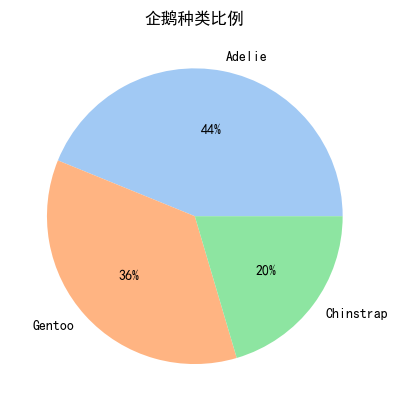

In [20]:
plt.pie(species_count, autopct='%.0f%%', labels=species_count.index)    # 第一个%表示格式字符串的开头，.0f表示保留零位小数，第二个%表示以百分号结尾
plt.title('企鹅种类比例')
plt.show()

可以看出，我们所取样的企鹅中，Adelie企鹅占比最高，Gentoo企鹅次之，Chinstrap企鹅最少。

### 企鹅所属岛屿比例

占比问题，依然采用饼图，步骤与上述类似，不再赘述。

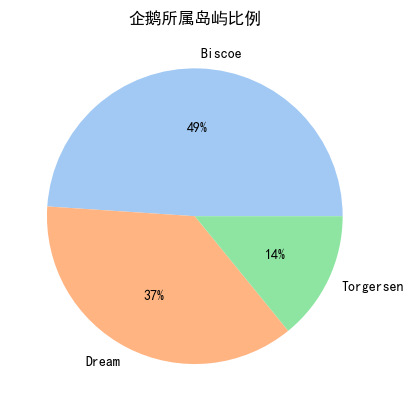

In [21]:
island_count = cleaned_data['island'].value_counts()
plt.pie(island_count, autopct='%.0f%%', labels=island_count.index)
plt.title('企鹅所属岛屿比例')
plt.show()

可以看出，将近一半的样本企鹅来自Biscoe，占比最高，其次是来自Dream，来自Torgersen的企鹅最少。

### 企鹅性别比例

占比问题，依然采用饼图，步骤与上述类似，不再赘述。


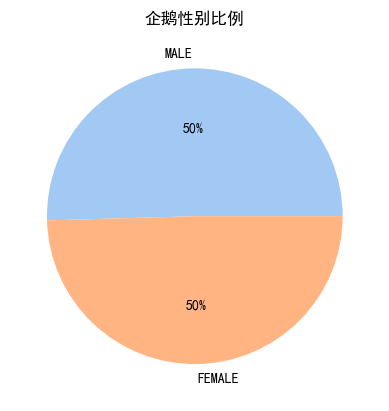

In [22]:
sex_count = cleaned_data['sex'].value_counts()
plt.pie(sex_count, autopct='%.0f%%', labels=sex_count.index)
plt.title('企鹅性别比例')
plt.show()

可见，样本企鹅的性别比例几乎为1：1，说明本次抽样随机性较好。

### 不同岛屿的不同企鹅种类数量

多变量问题，可以 `count_plot` 计算需要的数值，再利用复合条形图呈现数据。

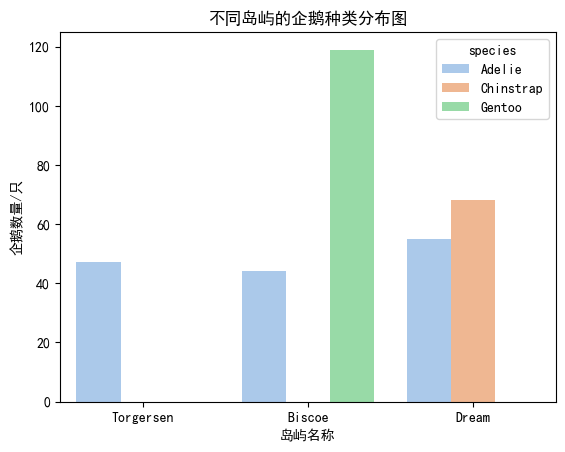

In [26]:
sns.countplot(cleaned_data, x='island', hue='species')  # countplot的y默认是数量
plt.title('不同岛屿的企鹅种类分布图')
plt.xlabel('岛屿名称')
plt.ylabel('企鹅数量/只')
plt.show()

可以发现Adelie企鹅广泛分布于三座岛屿，而Chinstrap企鹅仅在Dream分布，Gentoo企鹅仅在Biscoe分布。

### 不同岛屿的企鹅性别分布

采用与上述类似的方法来进行统计和绘图，这里不再赘述。

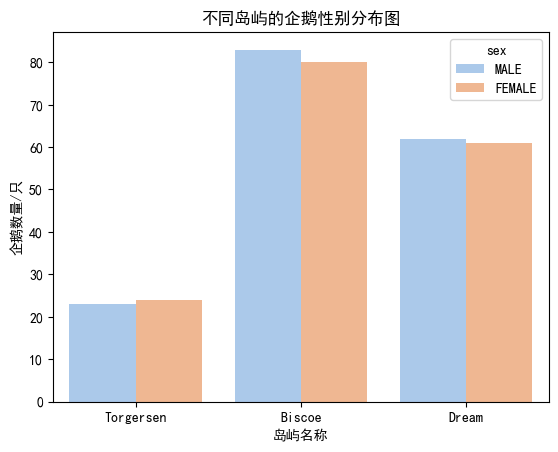

In [25]:
sns.countplot(cleaned_data, x='island', hue='sex')
plt.title('不同岛屿的企鹅性别分布图')
plt.xlabel('岛屿名称')
plt.ylabel('企鹅数量/只')
plt.show()

注意到，不同岛屿上抽样的企鹅性别比例也接近1：1，说明三座岛屿上企鹅的性别比例都较为均衡。

### 企鹅嘴峰长度与深度的关系

嘴峰的长度和深度都是数值变量，要探究两者之间是否存在关系可以通过散点图。

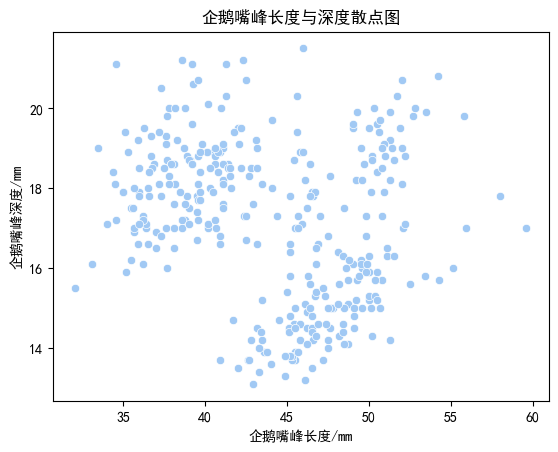

In [29]:
sns.scatterplot(cleaned_data, x='culmen_length_mm', y='culmen_depth_mm')
plt.title('企鹅嘴峰长度与深度散点图')
plt.xlabel('企鹅嘴峰长度/mm')
plt.ylabel('企鹅嘴峰深度/mm')
plt.show()

经观察，散点图中的点难以拟合到某个有规律的函数图像上，这与我们的常识不符。

注意到，我们在这一过程中是将全部的企鹅数据全部用来作图，这种杂乱的分布可能是种群不同导致的。接下来我们将按照企鹅所属种类来进行分类作图。

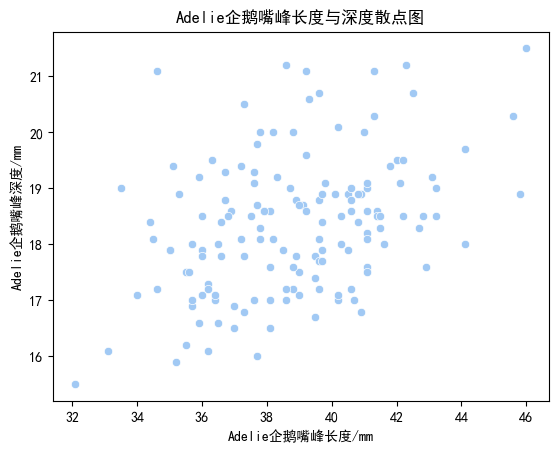

In [30]:
sns.scatterplot(cleaned_data[cleaned_data['species'] == 'Adelie'], x='culmen_length_mm', y='culmen_depth_mm')
plt.title('Adelie企鹅嘴峰长度与深度散点图')
plt.xlabel('Adelie企鹅嘴峰长度/mm')
plt.ylabel('Adelie企鹅嘴峰深度/mm')
plt.show()

发现依然没有显著的规律，因此可以做出推测，企鹅的嘴峰长度与深度之间可能并不存在强相关性。当然，样本量的较少也是问题之一。

### 企鹅体重与鳍长的关系

我们依然采用散点图分析，过程不再赘述。

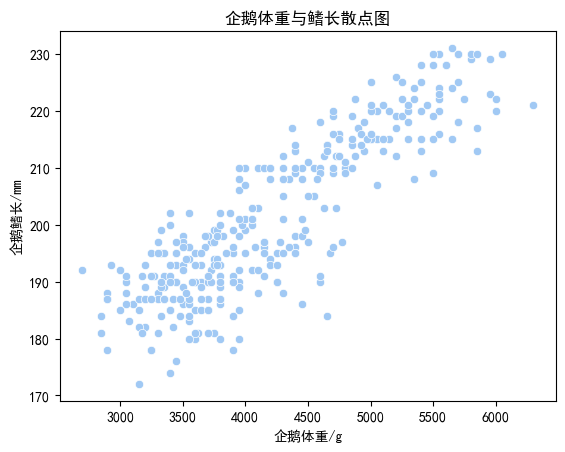

In [31]:
sns.scatterplot(cleaned_data, x='body_mass_g', y='flipper_length_mm')
plt.title('企鹅体重与鳍长散点图')
plt.xlabel('企鹅体重/g')
plt.ylabel('企鹅鳍长/mm')
plt.show()

观察到企鹅体重与鳍长之间存在一定的线性关系，后续可以考虑建立二元线性回归模型进一步研究。

### 企鹅体重与嘴峰深度的关系

考虑到企鹅的种类也可能会对嘴峰深度产生影响，因此我们可以用不同颜色区分不同种群，从而使散点图更加清晰可读。

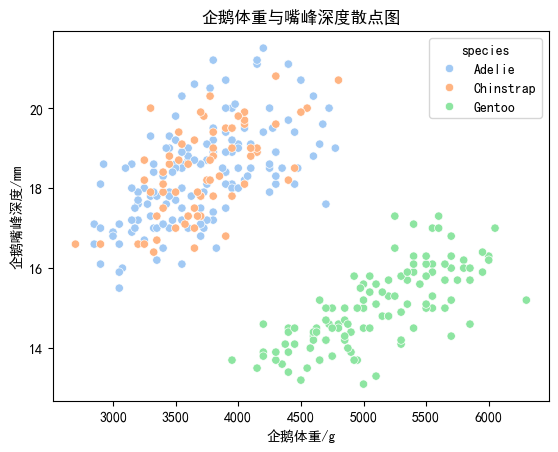

In [32]:
sns.scatterplot(cleaned_data, x='body_mass_g', y='culmen_depth_mm', hue='species')
plt.title('企鹅体重与嘴峰深度散点图')
plt.xlabel('企鹅体重/g')
plt.ylabel('企鹅嘴峰深度/mm')
plt.show()

可以看到，当我们把所有数据点都混在一起观察时很难看出明显的线性关系，但一旦用颜色区分就会发现在种群内部企鹅体重与嘴峰深度是有正相关关系的，可以拟合到一条直线上。后续可以利用线性回归模型进一步研究，甚至进行数值推测。

### 嘴峰长度分布与种群的关系

嘴峰长度分布本身是一个单变量问题，用直方图或密度图都能较好表示，种群的区分可以通过不同颜色来实现。

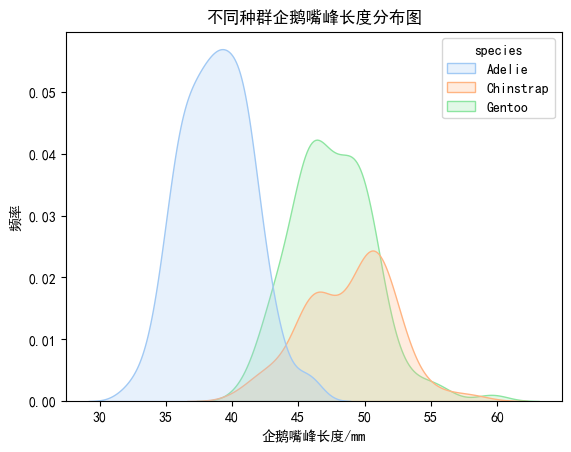

In [37]:
sns.kdeplot(cleaned_data, x='culmen_length_mm', fill=True, hue='species')
plt.title('不同种群企鹅嘴峰长度分布图')
plt.xlabel('企鹅嘴峰长度/mm')
plt.ylabel('频率')
plt.show()

可以发现三种企鹅的嘴峰长度分布大致服从正态分布，这是一个合理的结果。从图表中也能直观读出三种企鹅嘴峰长度不同的集中分布范围。

### 更多数据表

由于牵涉到的量较多，受篇幅限制，不能将量与量之间的关系悉数展开分析，在此借助成对图 `pairplot` 将更多的数据图作出，以便后续按需取用。

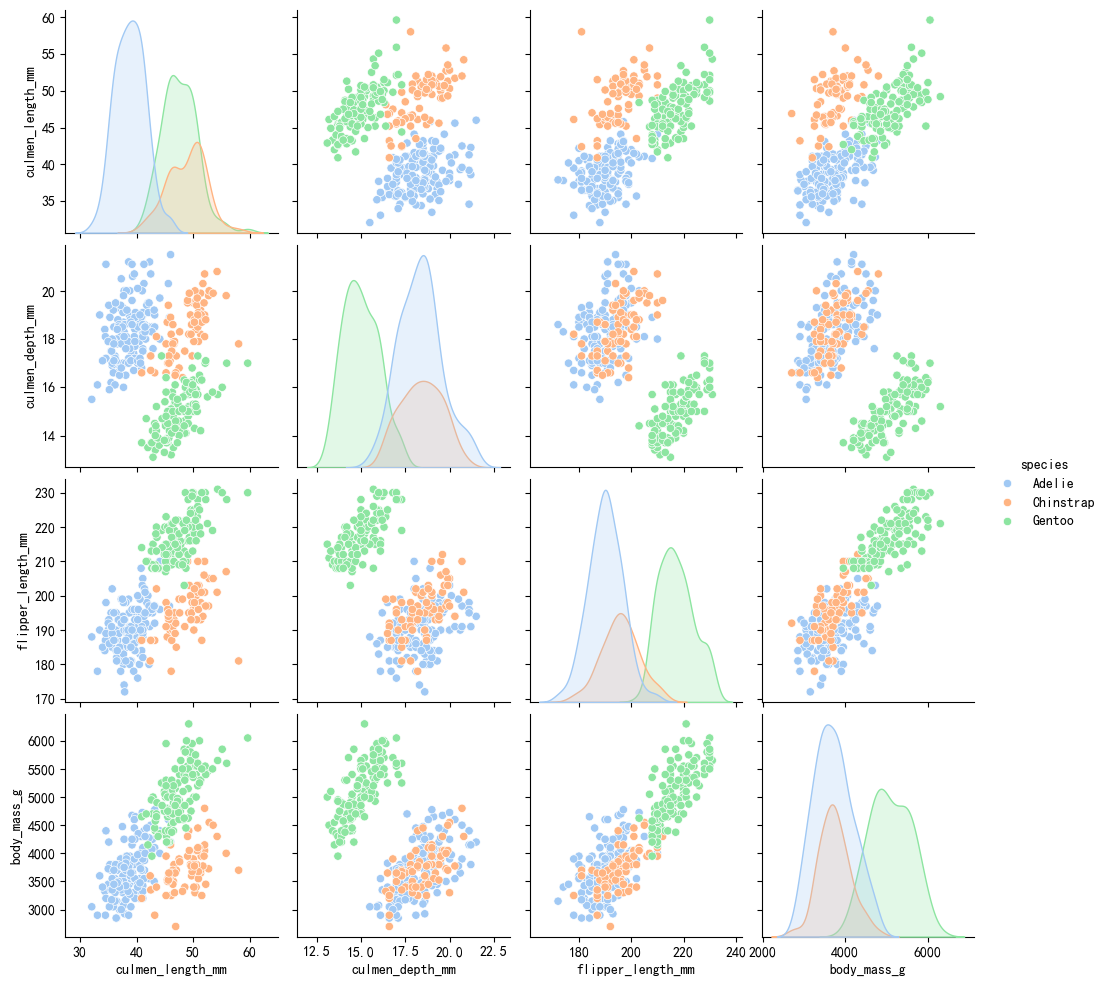

In [40]:
sns.pairplot(cleaned_data, hue='species')
plt.show()

由于性别也是一个很重要的影响因素，以下再将各数据图按性别区分标色的结果展示出来。

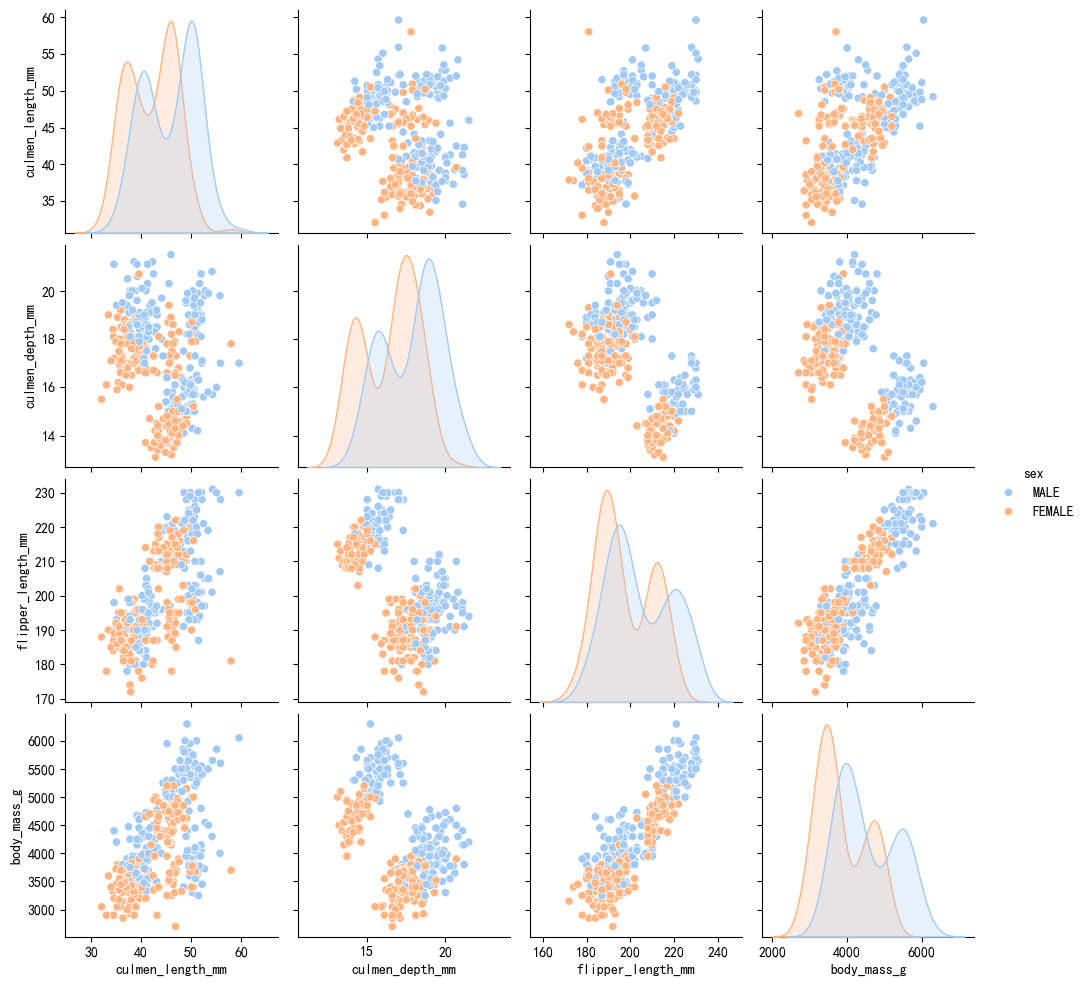

In [41]:
sns.pairplot(cleaned_data, hue='sex')
plt.show()

可以观察到，雄性企鹅的各项数值平均都要比雌性企鹅更高。

以上就是数据可视化的全部内容。